# E1 · Decompose
*Step 1 of network-spectral-predictor · pendulums on springs · actual = generated world, nominal = prediction*

Do the two learned maps mean something physical: K a lone pendulum, M a spring?

**Where we're at.** Step 1, rung 1. The simulator is calibrated (E0).

**Where the system is after the last experiments.** The ground truth agrees with the exact step to about 10⁻⁵ at 10 s. Nothing has been learned yet.

**Where we want it.** K and M that are the body and the spring, with ω₀² and κ readable from them.

**How this set moves it.** Fits K and M jointly on every gate pattern of a path of 3; checks them against the closed form, the frozen-bodies fit and gradient descent; then asks how much data a decomposed model needs compared with one global map.

In [1]:
%config InlineBackend.figure_format = 'retina'
import sys
from pathlib import Path
import numpy as np
from IPython.display import display
STUDY = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(STUDY))
import figures as F
from nsp import config, graphs, viz, world as W
F.setup()
cfg = F.cfg("e1")
world = config.world_from(cfg)
p = cfg["e1"]

In [2]:
F.ledger("e1")

**Configuration ledger**

| Setting | Value | Meaning |
| --- | --- | --- |
| `world.omega0` | 2.0 | a lone pendulum's frequency (rad/s) |
| `world.kappa` | 1.0 | spring stiffness ÷ inertia (1/s²) |
| `world.dt` | 0.05 | sampling step (s) |
| `world.d` | 1 | position coordinates per body (1 = planar) |
| `run.seeds` | [0, 1, 2] | seeds run (kept low on purpose) |
| `graph` | path | how the springs are wired |
| `n` | 3 | number of bodies |
| `amplitude` | 0.1 | starting swing size (rad) |
| `train_trajectories` | 10 | trajectories per training configuration |
| `train_steps` | 200 | steps per training trajectory |
| `test_trajectories` | 10 | trajectories per test |
| `test_steps` | 200 | steps per test rollout (200 = 10 s) |
| `gd_tolerance` | 1e-08 | gradient descent stops this close to the closed form |
| `scarcity_graph` | ring | graph for the data-efficiency check |
| `scarcity_n` | 8 | its bodies |
| `scarcity_steps` | [10, 20, 50, 100, 200, 500, 2000] | training steps tried (one trajectory) |
| `noise` | [0.0, 0.001, 0.01] | measurement noise, fraction of the swing |

## The question

One least-squares solve over every body, step and gate pattern:

$$\underbrace{x_v(t+1)}_{\text{next state of body } v} = \underbrace{K\,x_v(t)}_{\text{body alone}} \;-\; \underbrace{M}_{\text{spring map}}\sum_{u\sim v}\underbrace{g_{uv}}_{\text{gate}}\,\big(x_v(t)-x_u(t)\big)$$

The closed form says what the answer should be (from expanding the exact step in $\lambda$):

$$K_0 = e^{A_0\Delta t}, \qquad M_0 = \kappa\begin{bmatrix}\tfrac{\Delta t^2}{2} & \tfrac{\Delta t^3}{6}\\[2pt] \Delta t-\tfrac{\omega_0^2\Delta t^3}{3} & \tfrac{\Delta t^2}{2}\end{bmatrix} + O(\Delta t^4)$$

**Prediction.** $K$ within $10^{-4}$ of $K_0$ and $\hat\kappa$ within 0.2%; the frozen-bodies $K$ equals $K_0$ exactly; gradient descent lands on the least-squares answer.
**Pass if** $K$ and $M$ are within 1% of $K_0$ and $M_0$, and $\hat\omega_0^2$ and $\hat\kappa$ within 1%.

In [3]:
runs = F.ensure_results("e1")

e1: 3 seeds loaded (code fb79448, run 2026-11-25T20:28:47+00:00)


## The world: every gate pattern of a path of 3

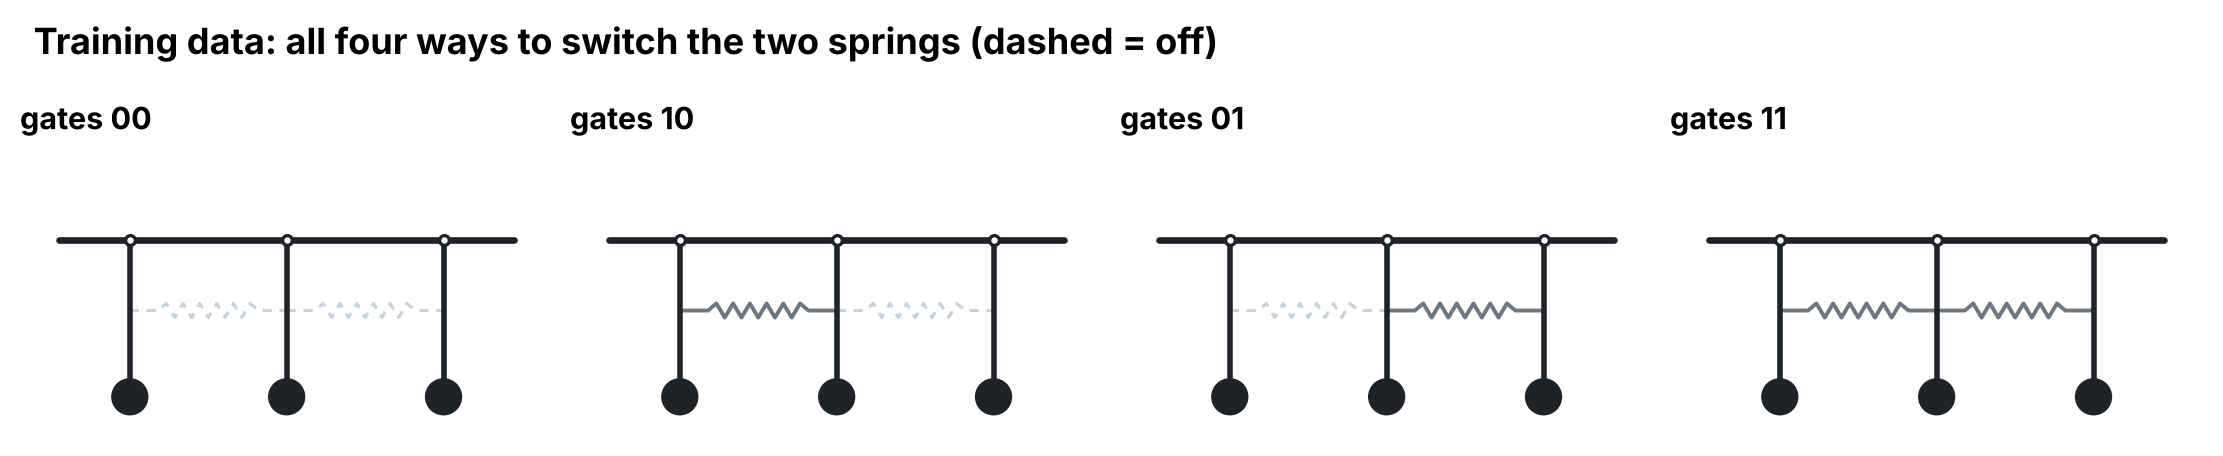

In [4]:
e = graphs.path(3)
F.schematics([(f"gates {int(g[0])}{int(g[1])}", 3, e, g) for g in graphs.all_gate_patterns(2)],
             title="Training data: all four ways to switch the two springs (dashed = off)");

## Nominal vs actual

Press **Play** to watch at real speed, or drag the slider. Actual bobs are filled, nominal bobs are hollow, and the whisker between them is the deviation, magnified (pick the factor) and coloured against the tolerance, like a CMM deviation plot. The trace underneath is the largest deviation over time.

First, a lone pendulum predicted by **K alone**; training never showed the model a single isolated body. Then the path of 3, predicted by the assembled model $I_3\otimes K - L\otimes M$ for 10 s with no correction.

In [5]:
a = runs[0]["arrays"]
tol = 0.01 * p["amplitude"]
display(viz.player(a["theta_act_lone"].T, a["theta_nom_lone"].T, [], dt=world.dt, tol=tol,
                   title="Three lone pendulums, each predicted by K alone",
                   subtitle="Tolerance: 1% of the 0.1 rad swing."))
display(viz.player(a["theta_act"], a["theta_nom"], graphs.path(3), dt=world.dt, tol=tol,
                   title="Path of 3, all springs on: assembled model (nominal) against the world (actual)",
                   subtitle="Free-running for 10 s from the first state."))

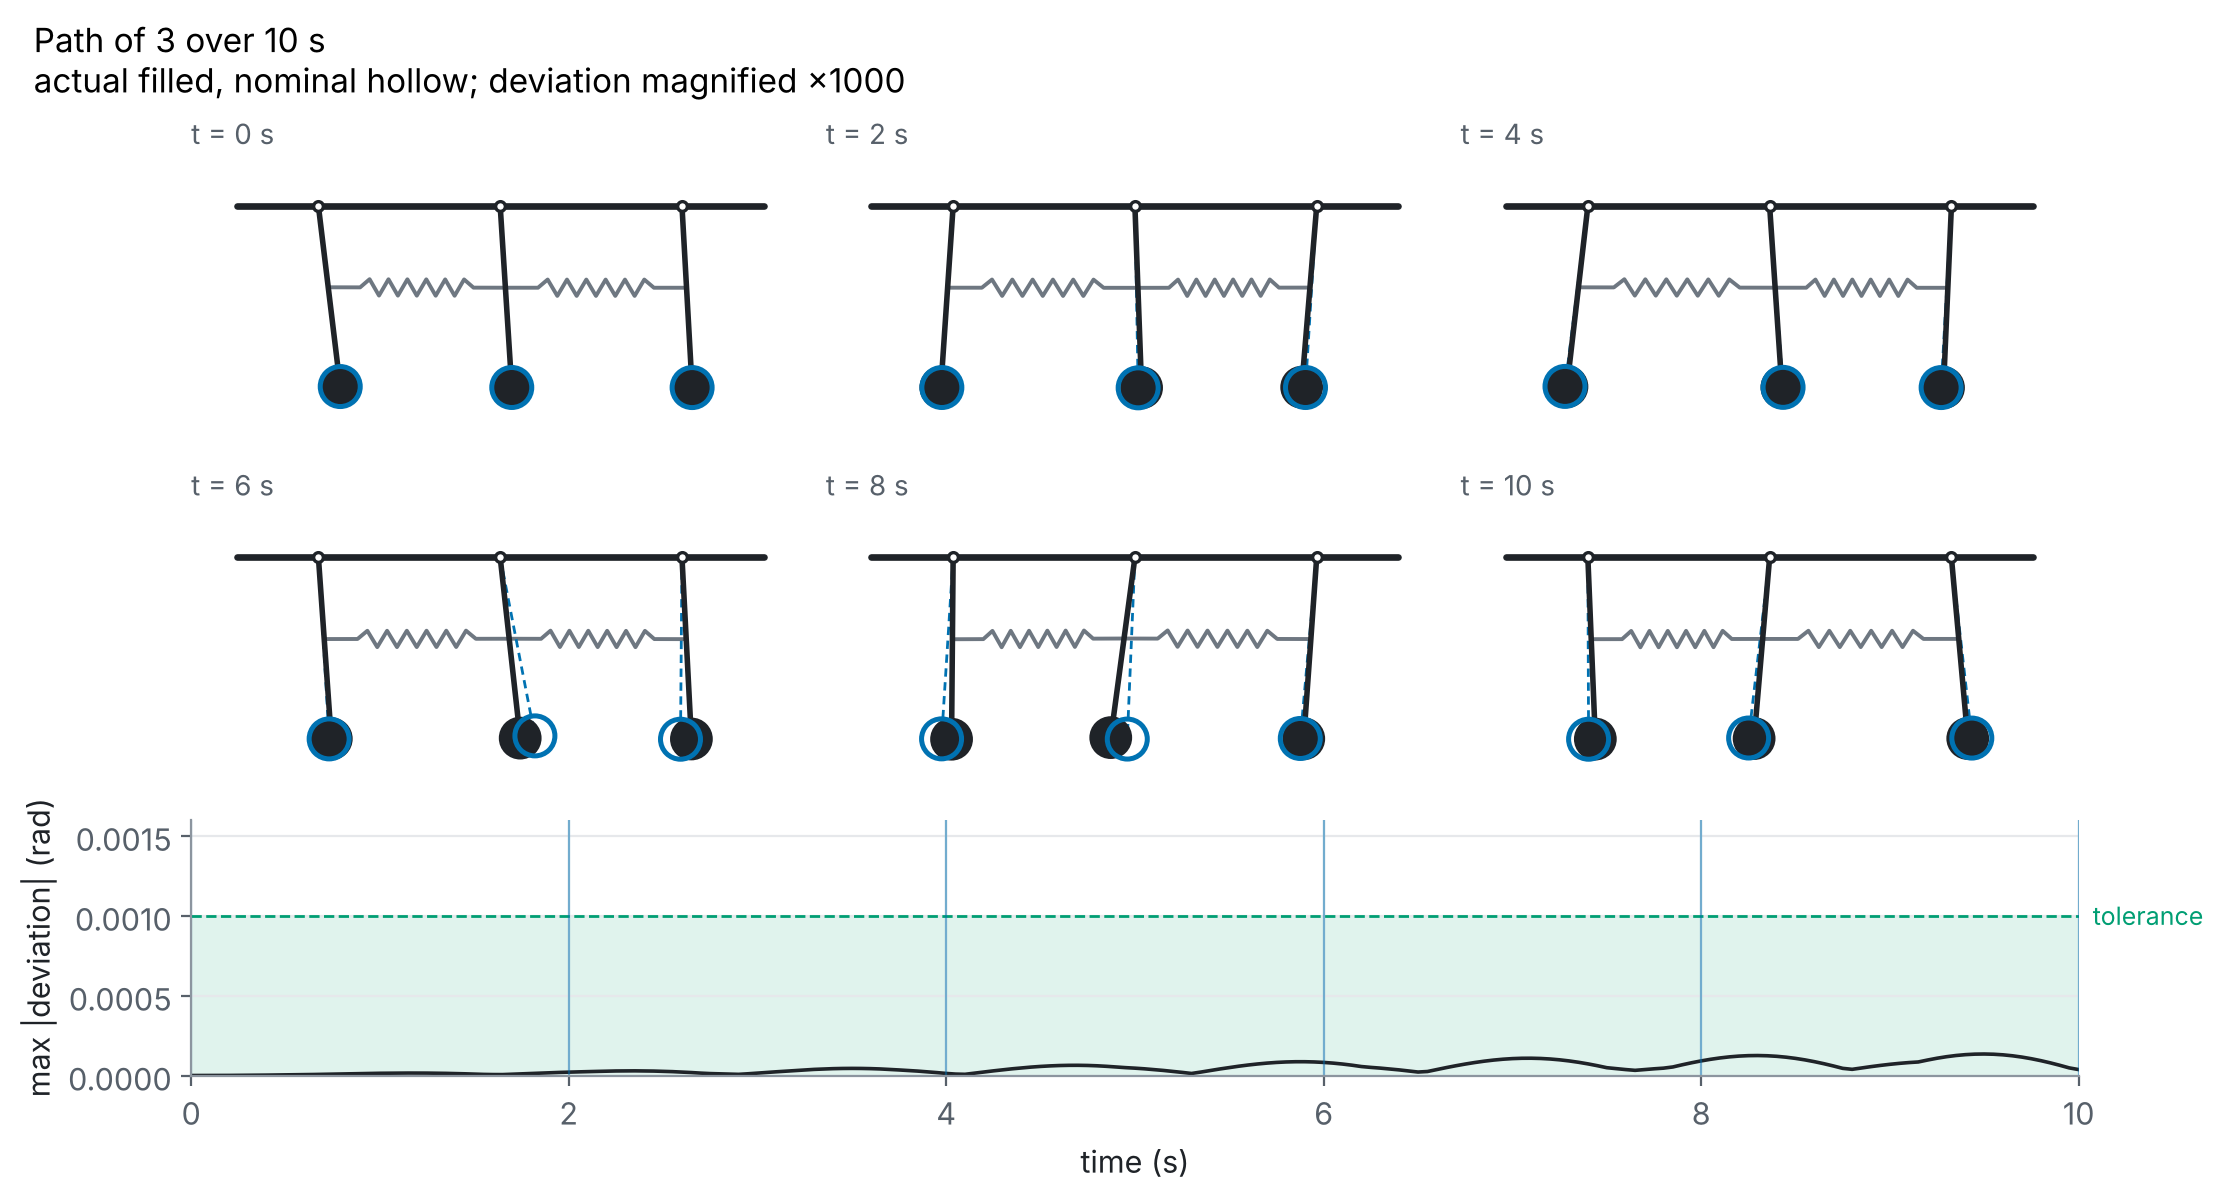

In [6]:
viz.film_strip(a["theta_act"], a["theta_nom"], graphs.path(3), dt=world.dt, tol=tol,
               title="Path of 3 over 10 s");

## K and M against the closed form

In [7]:
m = runs[0]["metrics"]
K, M, K0, M0 = (np.array(m[k]) for k in ("K", "M", "K0", "M0"))
rows = []
for name, A, A0 in (("K", K, K0), ("M", M, M0)):
    tol = 0.01 * np.abs(A0).max()
    for i in range(2):
        for j in range(2):
            rows.append({"characteristic": f"{name}{i + 1}{j + 1}", "nominal": A[i, j], "actual": A0[i, j],
                         "deviation": A0[i, j] - A[i, j], "tolerance": tol})
viz.inspection_report(rows, title="Seed 0: fitted (nominal) against closed form (actual); tolerance 1% of the largest entry")

**Seed 0: fitted (nominal) against closed form (actual); tolerance 1% of the largest entry**

| Characteristic | Nominal (predicted) | Actual (generated) | Deviation | Tolerance | Status |
| --- | --- | --- | --- | --- | --- |
| K11 | 0.995 | 0.995 | 4.744 × 10⁻⁸ | ±0.00995 | ✓ **in** |
| K12 | 0.04992 | 0.04992 | 5.999 × 10⁻¹⁰ | ±0.00995 | ✓ **in** |
| K21 | −0.1997 | −0.1997 | 3.792 × 10⁻⁶ | ±0.00995 | ✓ **in** |
| K22 | 0.995 | 0.995 | 6.112 × 10⁻⁸ | ±0.00995 | ✓ **in** |
| M11 | 0.001247 | 0.001248 | 6.466 × 10⁻⁷ | ±4.983 × 10⁻⁴ | ✓ **in** |
| M12 | 2.081 × 10⁻⁵ | 2.081 × 10⁻⁵ | 6.398 × 10⁻⁹ | ±4.983 × 10⁻⁴ | ✓ **in** |
| M21 | 0.04978 | 0.04983 | 5.170 × 10⁻⁵ | ±4.983 × 10⁻⁴ | ✓ **in** |
| M22 | 0.001247 | 0.001248 | 6.462 × 10⁻⁷ | ±4.983 × 10⁻⁴ | ✓ **in** |

In [8]:
F.say(f"Across seeds K is within {F.spread([r['metrics']['dK'] for r in runs])} of K₀ and M within "
      f"{F.spread([r['metrics']['dM'] for r in runs])} of M₀ (largest entry). The frozen-bodies K matches K₀ to "
      f"{F.spread([r['metrics']['dK_frozen'] for r in runs])}, and its M agrees with the joint fit's to "
      f"{F.spread([r['metrics']['dM_frozen_joint'] for r in runs])}: the joint fit does not trade body against spring.")

> **Finding.** Across seeds K is within 4.66 × 10⁻⁶ (3.79 × 10⁻⁶ to 5.11 × 10⁻⁶) of K₀ and M within 5.31 × 10⁻⁵ (5.17 × 10⁻⁵ to 5.53 × 10⁻⁵) of M₀ (largest entry). The frozen-bodies K matches K₀ to 5.18 × 10⁻¹⁶ (1.11 × 10⁻¹⁶ to 7.77 × 10⁻¹⁶), and its M agrees with the joint fit's to 2.12 × 10⁻⁶ (1.76 × 10⁻⁶ to 2.39 × 10⁻⁶): the joint fit does not trade body against spring.

## The physics, read back

$$\hat\omega_0^2 = -\Big[\tfrac{1}{\Delta t}\log K\Big]_{21}, \qquad \hat\kappa = \frac{M_{21}}{\Delta t - \hat\omega_0^2\Delta t^3/3}$$

In [9]:
mean = lambda k: float(np.mean([r["metrics"][k] for r in runs]))
viz.inspection_report([
    {"characteristic": "ω₀² (rad²/s²)", "nominal": mean("omega0_sq"), "actual": world.omega0**2,
     "deviation": world.omega0**2 - mean("omega0_sq"), "tolerance": 0.01 * world.omega0**2},
    {"characteristic": "κ (1/s²)", "nominal": mean("kappa"), "actual": world.kappa,
     "deviation": world.kappa - mean("kappa"), "tolerance": 0.01 * world.kappa},
    {"characteristic": "κ without the Δt³ correction", "nominal": mean("kappa_bare"), "actual": world.kappa,
     "deviation": world.kappa - mean("kappa_bare"), "tolerance": 0.01 * world.kappa},
], title="Physical parameters, mean over seeds")

**Physical parameters, mean over seeds**

| Characteristic | Nominal (predicted) | Actual (generated) | Deviation | Tolerance | Status |
| --- | --- | --- | --- | --- | --- |
| ω₀² (rad²/s²) | 4 | 4 | −9.335 × 10⁻⁵ | ±0.04 | ✓ **in** |
| κ (1/s²) | 0.9989 | 1 | 0.001063 | ±0.01 | ✓ **in** |
| κ without the Δt³ correction | 0.9956 | 1 | 0.004393 | ±0.01 | ✓ **in** |

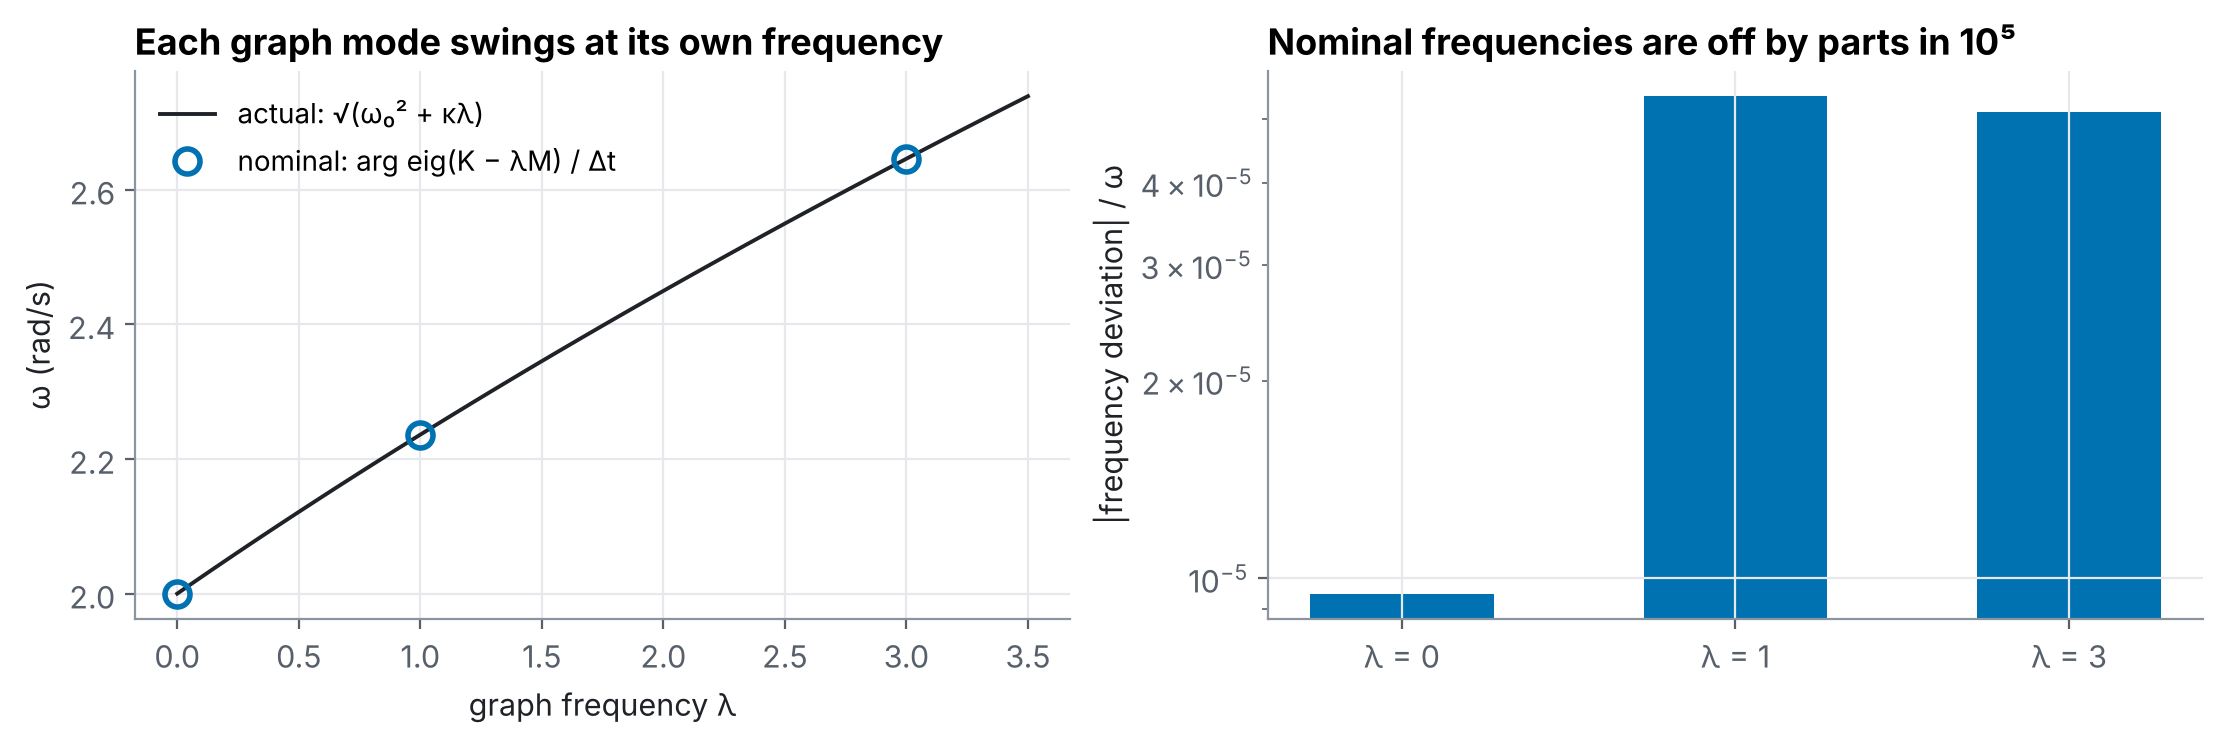

In [10]:
F.e1_frequencies(runs[0], world);

## Three ways to fit, one answer

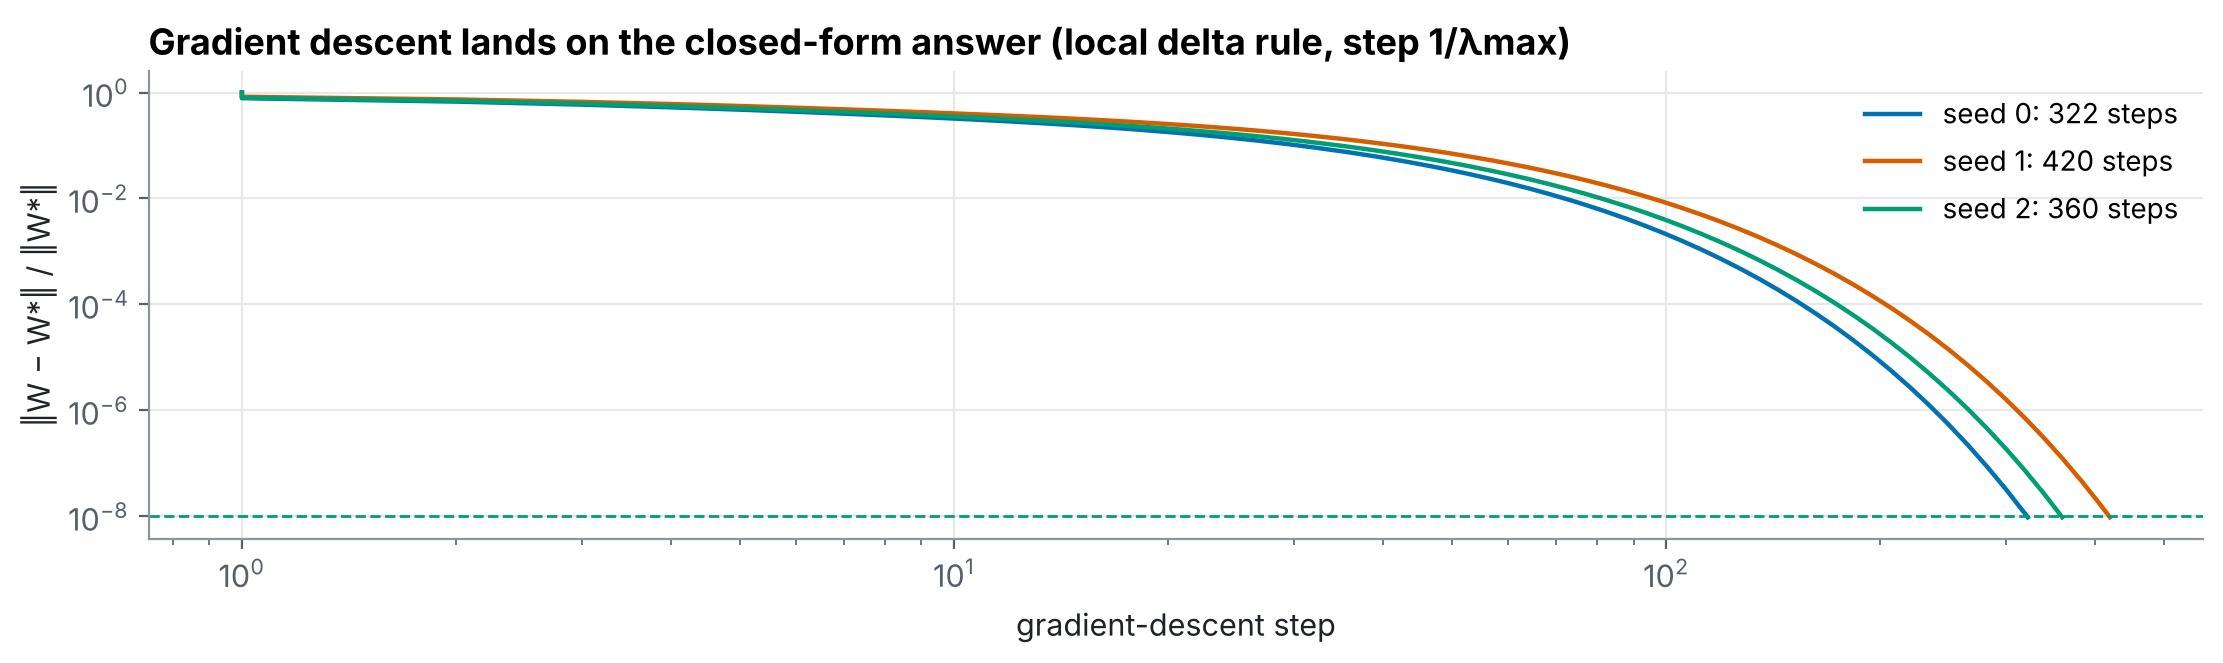

In [11]:
F.e1_gradient_descent(runs);

In [12]:
F.say(f"Gradient descent, using only each body's error times its own inputs, reaches the closed-form answer to 10⁻⁸ "
      f"in {F.spread([r['metrics']['gd_iterations'] for r in runs])} steps; the condition number of the data is "
      f"{F.spread([r['metrics']['condition'] for r in runs])}.")

> **Finding.** Gradient descent, using only each body's error times its own inputs, reaches the closed-form answer to 10⁻⁸ in 367 (322 to 420) steps; the condition number of the data is 21 (18.5 to 23.9).

## Why decompose: data efficiency

A ring of 8 fitted from **one trajectory**: nsp's 8 shared numbers against one global map of $16\times16 = 256$. A ring has repeated graph frequencies (pairs of modes with the same $\lambda$), and one trajectory only ever excites one direction of each pair, so six of the sixteen state directions are never seen. A global map cannot learn what it never sees; nsp's numbers are pinned down by every body at once.

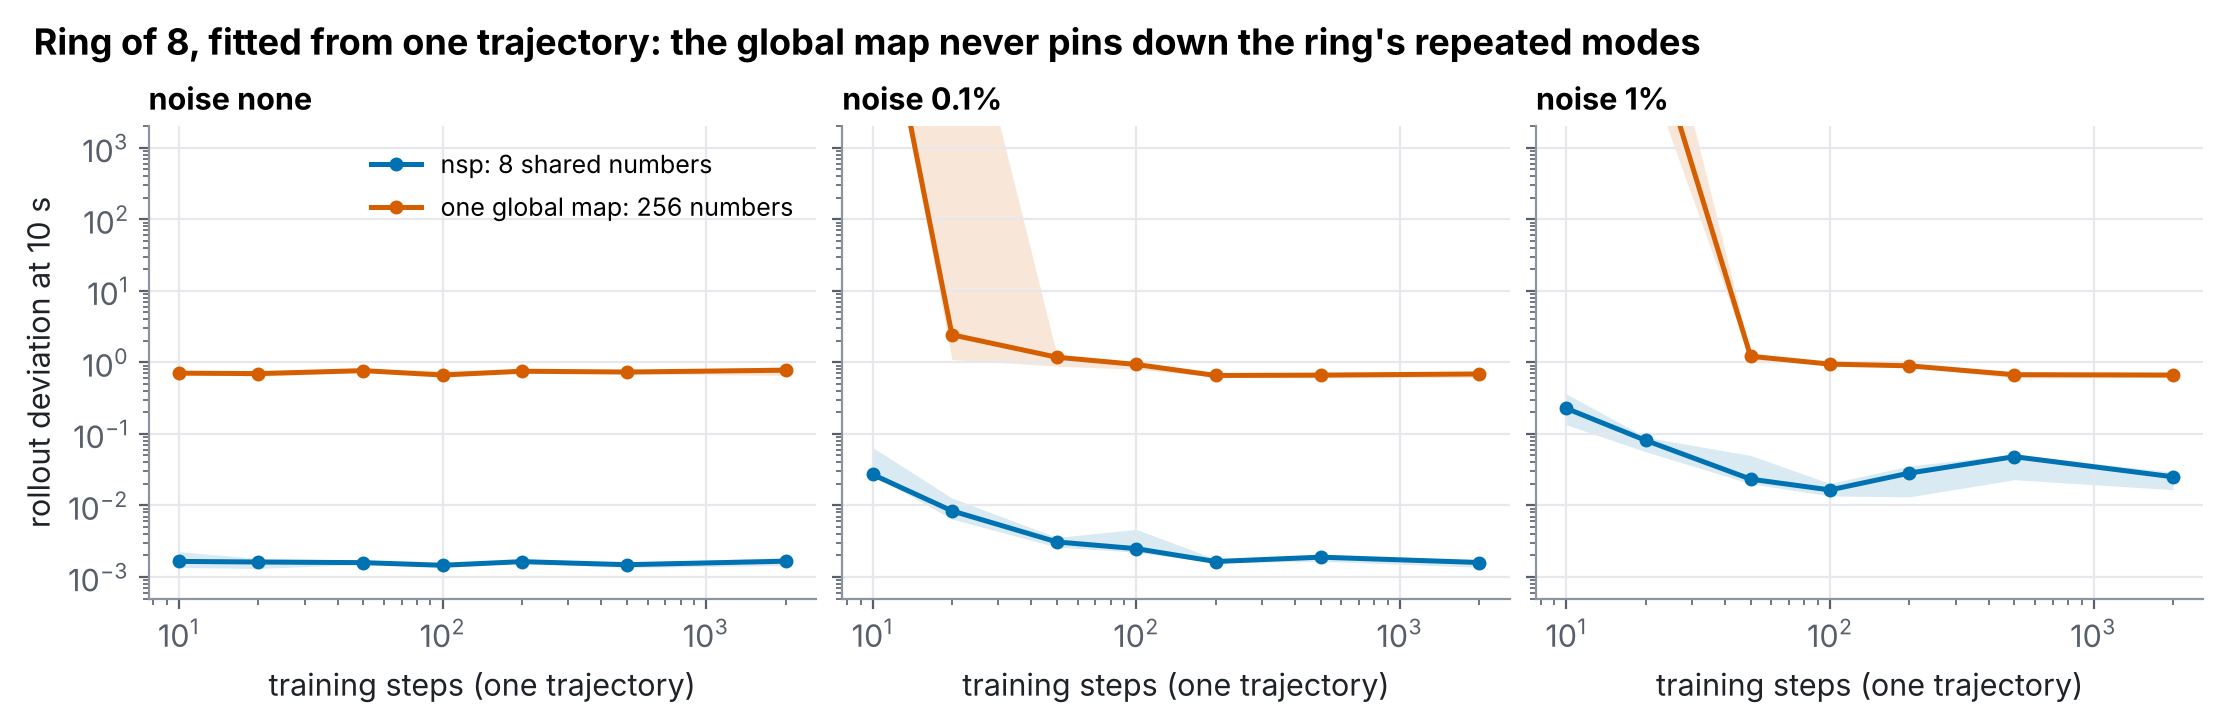

In [13]:
F.e1_scarcity(runs);

In [14]:
a = [r["arrays"] for r in runs]
F.say(f"From 2,000 clean steps the global map still misses by {F.spread([x['global_roll'][-1, 0] for x in a])} at 10 s, "
      f"while nsp misses by {F.spread([x['nsp_roll'][-1, 0] for x in a])}. At 1% noise nsp settles near "
      f"{F.spread([x['nsp_roll'][-1, -1] for x in a])}: noise in the inputs biases least squares, and more data does not remove "
      "that bias (errors in variables).")

> **Finding.** From 2,000 clean steps the global map still misses by 0.77 (0.658 to 0.874) at 10 s, while nsp misses by 0.00166 (0.00145 to 0.00187). At 1% noise nsp settles near 0.0237 (0.0166 to 0.0292): noise in the inputs biases least squares, and more data does not remove that bias (errors in variables).

## Inspection report

In [15]:
viz.inspection_report([
    {"characteristic": "max |K − K₀|", "deviation": mean("dK"), "tolerance": 0.01 * np.abs(K0).max()},
    {"characteristic": "max |M − M₀|", "deviation": mean("dM"), "tolerance": 0.01 * np.abs(M0).max()},
    {"characteristic": "ω₀² recovered (relative)", "deviation": 1 - mean("omega0_sq") / world.omega0**2, "tolerance": 0.01},
    {"characteristic": "κ recovered (relative)", "deviation": 1 - mean("kappa") / world.kappa, "tolerance": 0.01},
    {"characteristic": "Path of 3, deviation at 10 s", "deviation": float(np.mean([r["metrics"]["path3"]["200"] for r in runs])),
     "tolerance": 0.01},
    {"characteristic": "Lone pendulum by K alone, deviation at 10 s",
     "deviation": float(np.mean([r["metrics"]["lone"]["200"] for r in runs])), "tolerance": 0.01},
])

**Inspection report**

| Characteristic | Nominal (predicted) | Actual (generated) | Deviation | Tolerance | Status |
| --- | --- | --- | --- | --- | --- |
| max |K − K₀| | — | — | 4.662 × 10⁻⁶ | ±0.00995 | ✓ **in** |
| max |M − M₀| | — | — | 5.311 × 10⁻⁵ | ±4.983 × 10⁻⁴ | ✓ **in** |
| ω₀² recovered (relative) | — | — | −2.334 × 10⁻⁵ | ±0.01 | ✓ **in** |
| κ recovered (relative) | — | — | 0.001063 | ±0.01 | ✓ **in** |
| Path of 3, deviation at 10 s | — | — | 9.835 × 10⁻⁴ | ±0.01 | ✓ **in** |
| Lone pendulum by K alone, deviation at 10 s | — | — | 2.289 × 10⁻⁴ | ±0.01 | ✓ **in** |

## Log

In [16]:
F.log(runs)

| Seed | Code version | Run at (UTC) | Python | NumPy | SciPy |
| --- | --- | --- | --- | --- | --- |
| 0 | `fb79448` | 2026-11-25T20:28:47+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |
| 1 | `fb79448` | 2026-11-25T20:28:48+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |
| 2 | `fb79448` | 2026-11-25T20:28:49+00:00 | 3.13.18 | 2.5.3 | 1.18.1 |